In [1]:
from sklearn.datasets import fetch_california_housing
data = fetch_california_housing(as_frame=True).frame
data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
data.info()
print(data.isnull().sum())
print(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   14

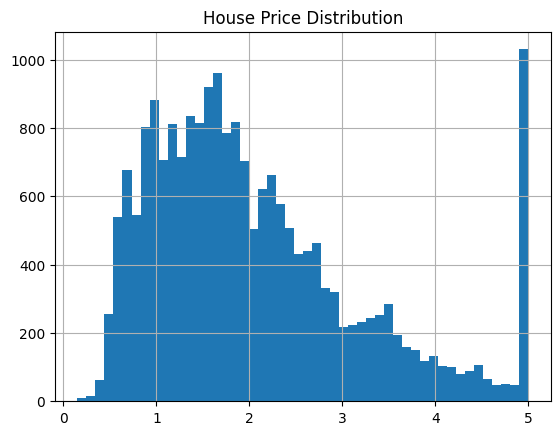

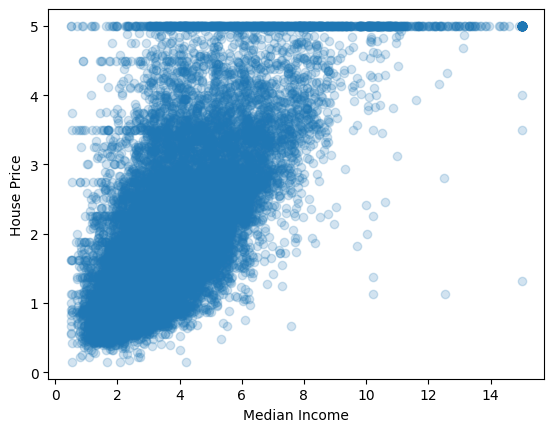

In [3]:
import matplotlib.pyplot as plt

data["MedHouseVal"].hist(bins=50)
plt.title("House Price Distribution")
plt.show()

plt.scatter(data["MedInc"], data["MedHouseVal"], alpha=0.2)
plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.show()

In [4]:
data = data[(data["AveRooms"] < 20) &
            (data["AveBedrms"] < 5) &
            (data["AveOccup"] < 10)]
print(data.shape)

from sklearn.model_selection import train_test_split

X = data.drop("MedHouseVal", axis=1)
y = data["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(20532, 9)
(16425, 8) (4107, 8)


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name)
    print("MAE :", mean_absolute_error(y_test, pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
    print("R2  :", r2_score(y_test, pred))
    print()

Linear Regression
MAE : 0.4941478222722732
RMSE: 0.6734959365361198
R2  : 0.658355211399053

Random Forest
MAE : 0.32956959627465315
RMSE: 0.5068236804969773
R2  : 0.8065277699342033



In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
best_model = grid.best_estimator_
pred = best_model.predict(X_test)
print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2  :", r2_score(y_test, pred))

Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
MAE : 0.3277076715120528
RMSE: 0.5042229084840316
R2  : 0.8085082856465636


In [7]:
import joblib, os
from google.colab import files

joblib.dump(best_model, "model.pkl", compress=3)
print(os.path.getsize("model.pkl") / 1e6, "MB")
files.download("model.pkl")

65.07236 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
small_model = RandomForestRegressor(
    n_estimators=100, max_depth=20, min_samples_leaf=2,
    random_state=42, n_jobs=-1
)
small_model.fit(X_train, y_train)
pred = small_model.predict(X_test)
print("MAE :", mean_absolute_error(y_test, pred))
print("R2  :", r2_score(y_test, pred))

joblib.dump(small_model, "model.pkl", compress=3)
print(os.path.getsize("model.pkl") / 1e6, "MB")
files.download("model.pkl")

MAE : 0.3290476032247153
R2  : 0.8067518269654008
17.832521 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>